# I04 — Cenozoic planktonic foraminifera on reconstructed paleo-latitude


**Cluster I: Paleo-biogeography.**
**Cenozoic planktonic foraminifera from the Paleobiology Database, most of them from DSDP/ODP/IODP drill cores. Reconstructs every sample to its age with `gplately` and plots the occurrences against paleo-latitude instead of present-day latitude.**

## Why this notebook is different from the original draft

An earlier draft of I04 used the Holocene/LGM ForCenS database. At 20 ka (LGM) the global plate-reconstruction displacement is \~40 m — negligible against the spatial resolution of any community-distribution map. The "reconstruction" step was therefore window-dressing. This rewritten I04 anchors the same conceptual workflow (community structure on paleo-coordinates) to a dataset where the reconstruction does real work: Cenozoic foraminifera at deep-sea sites that have moved tens of degrees of latitude through the Cenozoic.

## What this notebook produces

(i) A reconstructed paleo-map of foraminifera occurrences at three Cenozoic ages (60, 35, 10 Ma), coloured by genus; (ii) a paleo-latitude histogram per epoch; (iii) the paleo-latitude trajectories of the drill sites with the longest records — each site's path through latitude space across its sampled age range.

**Audience**: postgrad → researcher.
**Difficulty**: ★★★.

## Learning objectives

- Reconstruct a set of fixed drill-site coordinates to their per-occurrence sample ages with `gplately`.
- Distinguish present-day latitude (where you sample) from paleo-latitude (where the rock was deposited) — and explain why ignoring the distinction biases Cenozoic biogeography.
- Compute community-composition histograms vs paleo-latitude for binned epochs.
- Query the Paleobiology Database API and build a tidy occurrence table from its response.

## Prerequisites and runtime

- **Plate model**: Zahirovic 2022, paleomagnetic frame (anchor 701701).
- **Data**: live query of the Paleobiology Database (https://paleobiodb.org/) for Globigerinoidea and Globorotaliidae, 66–0 Ma: about 74,000 occurrences. If the API cannot be reached, the notebook reads the cached response of an earlier query, `data/foraminifera_cenozoic/pbdb_planktonic_forams_0_66Ma.csv.gz`.
- **Python**: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`, `matplotlib`.
- **Runtime**: \~2 minutes (the query returns about 30 MB).

## Why Zahirovic 2022 in the paleomagnetic frame (anchor 701701)

Mantle-frame plate models (moving-hotspot or tectonic-rules frames) place the plates relative to the deep mantle. For paleo-latitude work (comparing reconstructed proxy sites against the latitudinal climate constraints those proxies record), the mantle frame is systematically wrong: it differs from the spin-axis frame by cumulative true polar wander, which can be many degrees in the Cenozoic.

For this notebook we use **Zahirovic 2022** with `anchor_plate_id = 701701` — the synthetic anchor in the Z22 rotation file that puts the model in the **paleomagnetic reference frame** (African plate motion expressed as paleomag-rotation chain, not as moving-hotspot chain). Reconstructed paleo-latitudes are then directly comparable to paleomagnetic and paleoclimate constraints.


## Data availability

The occurrences come live from the Paleobiology Database API (https://paleobiodb.org/data1.2/occs/list.json) at runtime: every occurrence of Globigerinoidea and Globorotaliidae between 66 and 0 Ma, with present-day coordinates, age range and collection name. Most collections are DSDP/ODP/IODP core samples (collection names such as `321-U1338A-14H-CC`), from which the notebook takes the drill-site name. The response is saved to `data/foraminifera_cenozoic/pbdb_planktonic_forams_0_66Ma.csv.gz`, which the notebook reads only when the API cannot be reached. PBDB data are CC BY 4.0.

> **PBDB**: Paleobiology Database, https://paleobiodb.org/

The Neptune Sandbox (https://www.nsb-mfn-berlin.de/, registration required) holds the same kind of record with DSDP/ODP/IODP-aligned taxonomy and age models.

In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
from IPython.display import display, HTML

# Library versions (printed for reproducibility)
try:
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")

gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration

In [2]:
# === USER CONFIGURATION =====================================================
TAXA              = "Globigerinoidea,Globorotaliidae"   # planktonic foraminifera
AGE_WINDOW_MA     = (0.0, 66.0)
MAX_AGE_RANGE_MYR = 10.0     # drop occurrences dated only to a range wider than this
PBDB_BASE         = "https://paleobiodb.org/data1.2/occs/list.json"
CACHE_CSV         = "data/foraminifera_cenozoic/pbdb_planktonic_forams_0_66Ma.csv.gz"
MODEL_NAME        = "Zahirovic2022"
SNAPSHOT_TIMES_MA = (60.0, 35.0, 10.0)  # Paleocene, Eocene-Olig boundary, late Miocene
ANCHOR_PLATE_ID   = 701701   # Zahirovic 2022 paleomag-frame anchor (African plate, paleomag rotations)
PALEOLAT_BINS     = np.arange(-90, 95, 10)   # 10-deg bins
N_TRAJECTORY_SITES = 12      # drill sites with the longest records, for section 5
# ============================================================================

## 1. Load the foram occurrences

In [3]:
# Cell 2 — query PBDB (retry, then the cached response of an earlier query)
import time, requests

params = dict(base_name=TAXA, min_ma=AGE_WINDOW_MA[0], max_ma=AGE_WINDOW_MA[1],
              show="coords,coll", vocab="pbdb", limit="all")
COLS = ["occurrence_no", "collection_no", "collection_name", "accepted_name", "accepted_rank",
        "early_interval", "late_interval", "max_ma", "min_ma", "lng", "lat"]
raw = None
for attempt, delay in enumerate([0, 5, 15]):
    if delay: time.sleep(delay)
    try:
        r = requests.get(PBDB_BASE, params=params, timeout=300)
        r.raise_for_status()
        raw = pd.DataFrame(r.json()["records"]).reindex(columns=COLS)
        raw.to_csv(CACHE_CSV, index=False)
        print(f"  ✓ live PBDB query: {len(raw):,} occurrences (cache refreshed)")
        break
    except Exception as e:
        print(f"  ✗ attempt {attempt + 1} failed: {e}")
if raw is None:
    raw = pd.read_csv(CACHE_CSV)
    print(f"  → PBDB unreachable; loaded {len(raw):,} occurrences from the cached response {CACHE_CSV}")

df = raw.copy()
for c in ("max_ma", "min_ma", "lng", "lat"):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=["max_ma", "min_ma", "lng", "lat", "accepted_name"])
df = df[(df["max_ma"] - df["min_ma"]) <= MAX_AGE_RANGE_MYR].reset_index(drop=True)
df["age_ma"] = 0.5 * (df["max_ma"] + df["min_ma"])
df["genus"]  = df["accepted_name"].str.split().str[0]
df = df.rename(columns={"lng": "lon"})
# DSDP/ODP/IODP drill site from the collection name, e.g. '321-U1338A-14H-CC' -> '321-U1338'
_m = df["collection_name"].astype(str).str.extract(r"^(\d{1,3})-(U?\d{3,4})[A-Z]?\b")
df["site"] = (_m[0] + "-" + _m[1]).where(_m[0].notna())
print(f"  {len(df):,} occurrences dated to within {MAX_AGE_RANGE_MYR:g} Myr  |  "
      f"{df['collection_no'].nunique():,} collections  |  {df['site'].nunique()} drill sites  |  "
      f"{df['genus'].nunique()} genera")
print(f"  age range: {df.age_ma.min():.1f} – {df.age_ma.max():.1f} Ma")
df[["collection_name", "site", "accepted_name", "age_ma", "lon", "lat"]].head()

  ✓ live PBDB query: 73,854 occurrences (cache refreshed)


  69,581 occurrences dated to within 10 Myr  |  7,234 collections  |  138 drill sites  |  43 genera
  age range: 0.0 – 63.8 Ma


,collection_name,site,accepted_name,age_ma,lon,lat
0,Vogtle Electric Generating Plant,NaN,Globorotalia (Truncorotaloides),39.3700,-81.760559,33.143333
1,"Scanelle quarry, floatstones, Calbria, Italy",NaN,Sherbornina,9.4380,16.266666,39.183334
2,"Scanelle quarry, floatstones, Calbria, Italy",NaN,Orbulina,9.4380,16.266666,39.183334
3,"Scanelle quarry, floatstones, Calbria, Italy",NaN,Globigerinoides,9.4380,16.266666,39.183334
4,"Messadit section (Unit 2), Morocco",NaN,Globoconella conomiozea,6.2895,-3.000000,35.333332


## 2. Reconstruct each occurrence to its sample age

In [4]:
# Cell 3 — paleo-position of every sample at its own age
# Many occurrences share a sample (same location and age), so each distinct sample is
# rotated once: plate ID from the static polygons, then that plate's finite rotation.
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID)

samples = df[["lon", "lat", "age_ma"]].drop_duplicates().reset_index(drop=True)
pts = gplately.Points(recon, samples["lon"].values, samples["lat"].values,
                      anchor_plate_id=ANCHOR_PLATE_ID)
samples["plate_id"] = np.asarray(pts.plate_id, dtype=int)
paleo = []
for s in samples.itertuples():
    rot = recon.rotation_model.get_rotation(float(s.age_ma), int(s.plate_id),
                                            anchor_plate_id=ANCHOR_PLATE_ID)
    paleo.append((rot * pygplates.PointOnSphere(s.lat, s.lon)).to_lat_lon())
samples["paleo_lat"], samples["paleo_lon"] = zip(*paleo)
df = df.merge(samples, on=["lon", "lat", "age_ma"], how="left")
print(f"  reconstructed {len(samples):,} distinct samples ({len(df):,} occurrences)")

shift = (df["paleo_lat"] - df["lat"]).abs().median()
print(f"  median |Δlatitude| from reconstruction: {shift:.1f}°  (compare to ~0.0° for LGM)")

  reconstructed 1,228 distinct samples (69,581 occurrences)
  median |Δlatitude| from reconstruction: 0.7°  (compare to ~0.0° for LGM)


## 3. Per-snapshot paleogeographic map of forams coloured by genus


  60 Ma: 399 occurrences in ±5 Myr window


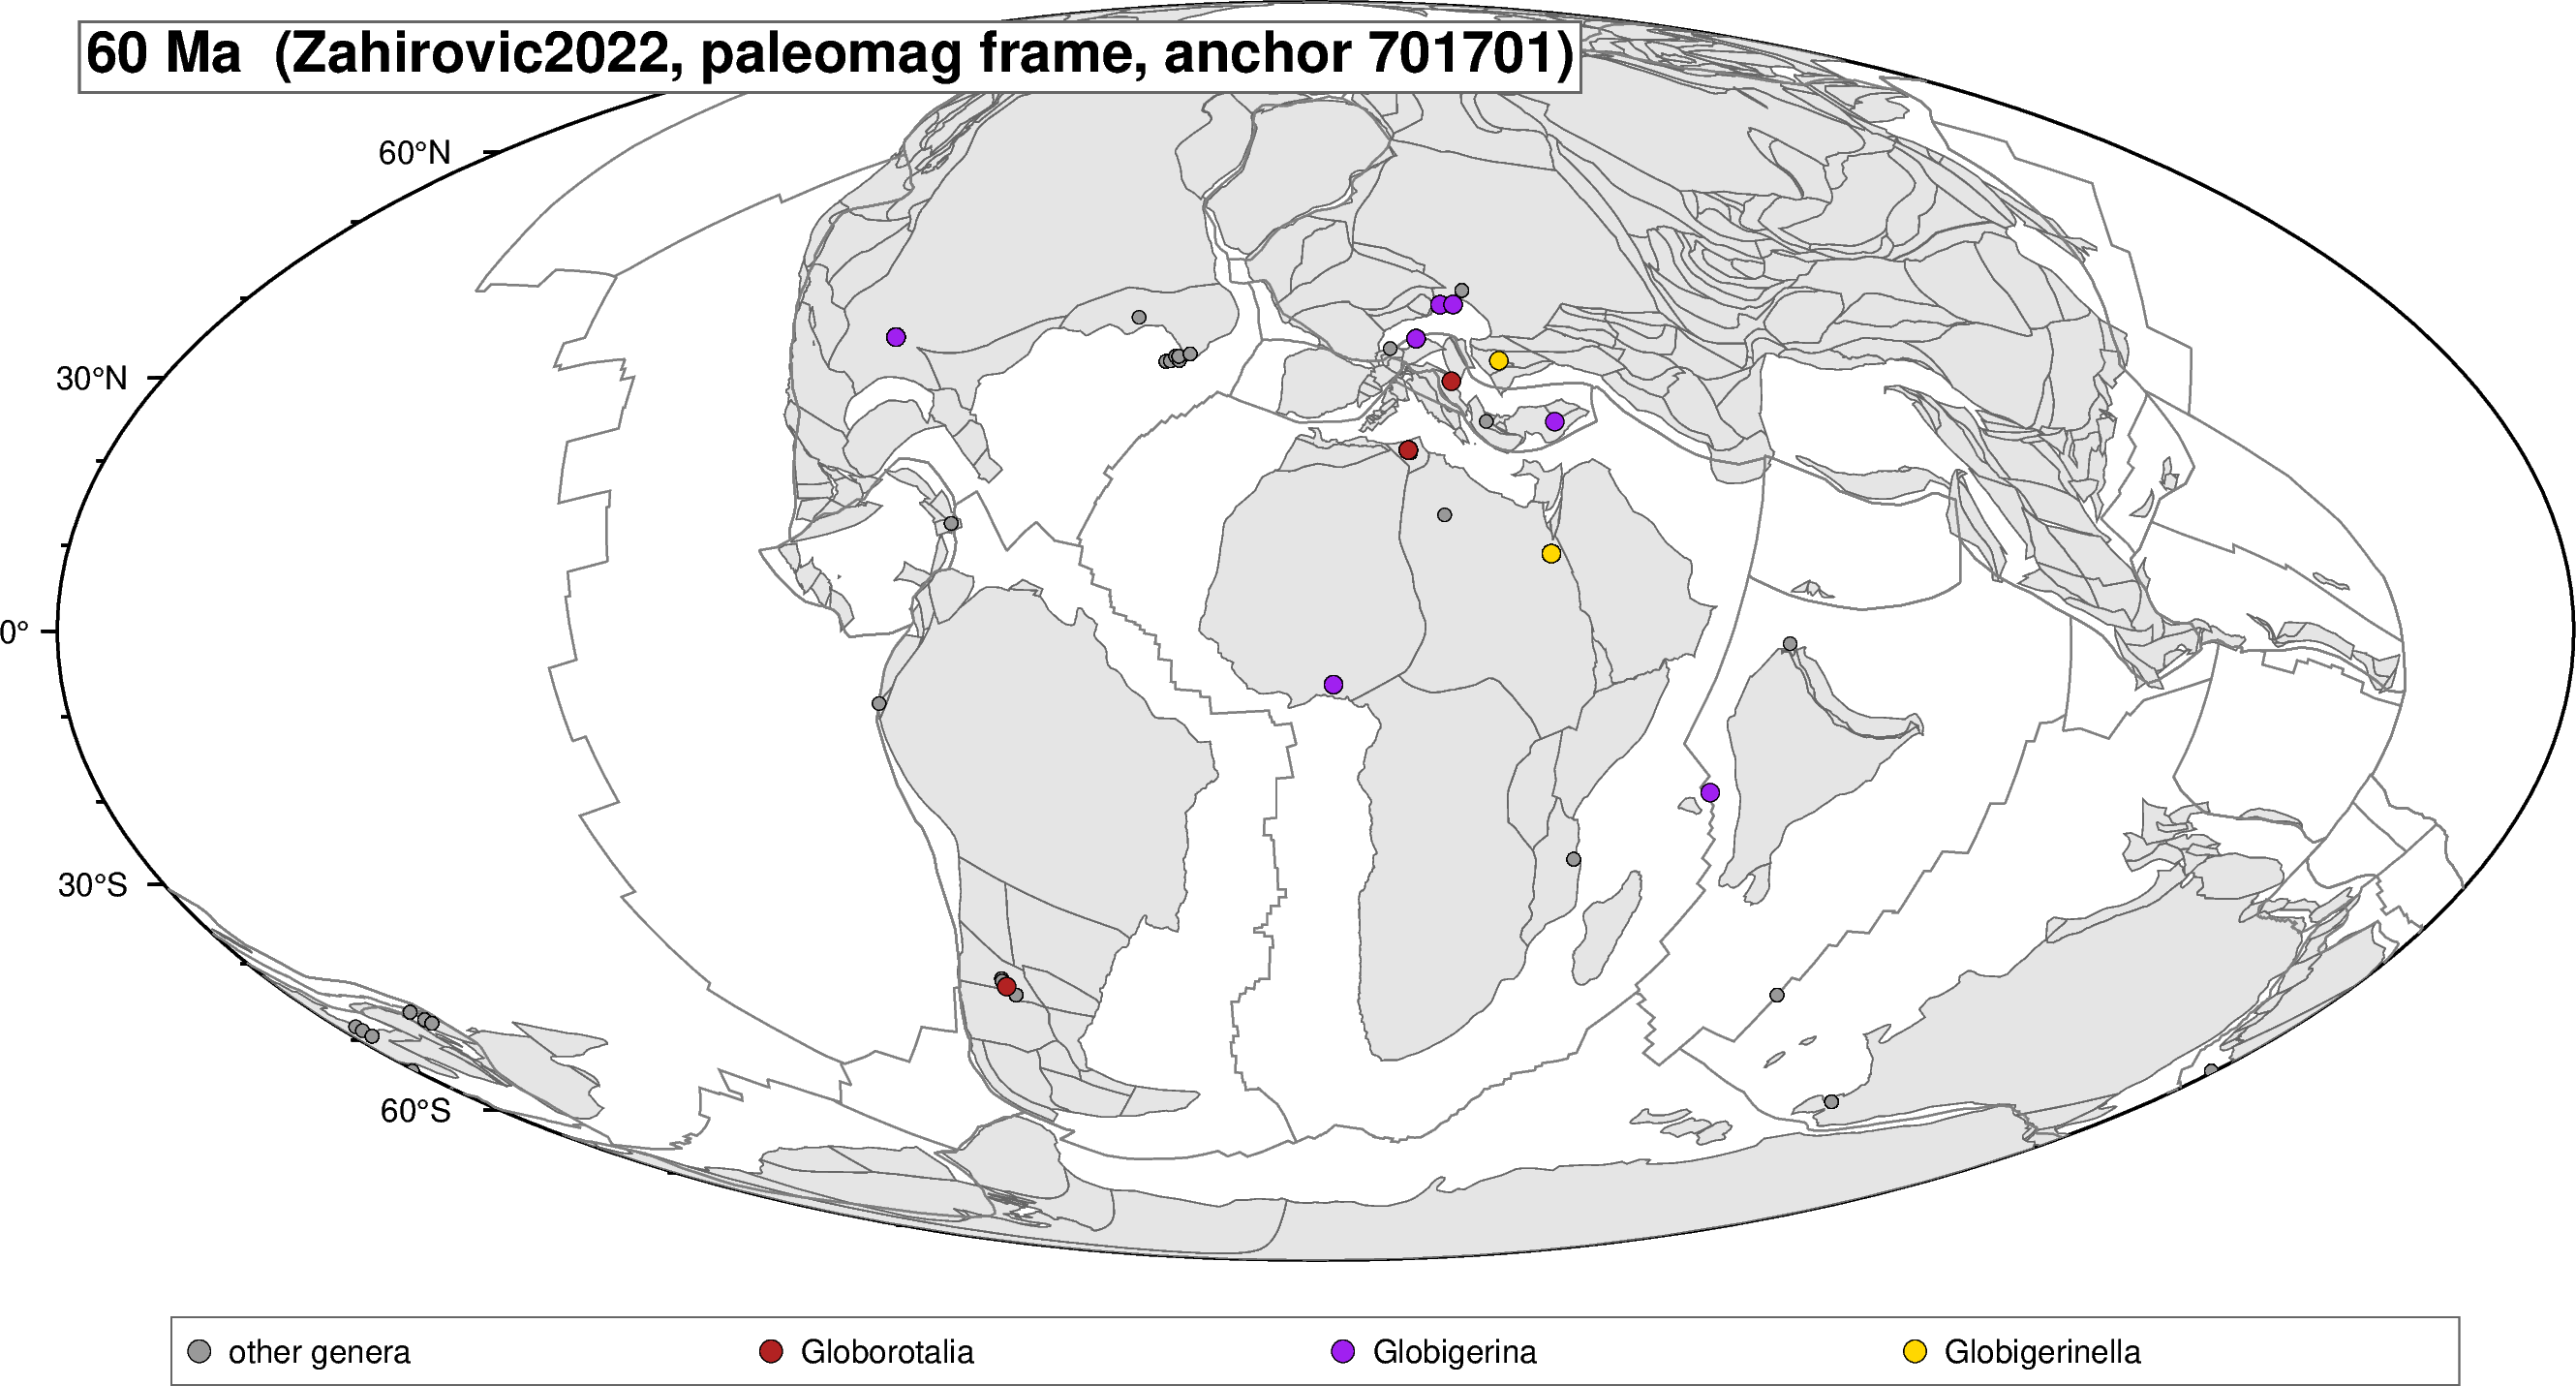

  35 Ma: 1,209 occurrences in ±5 Myr window


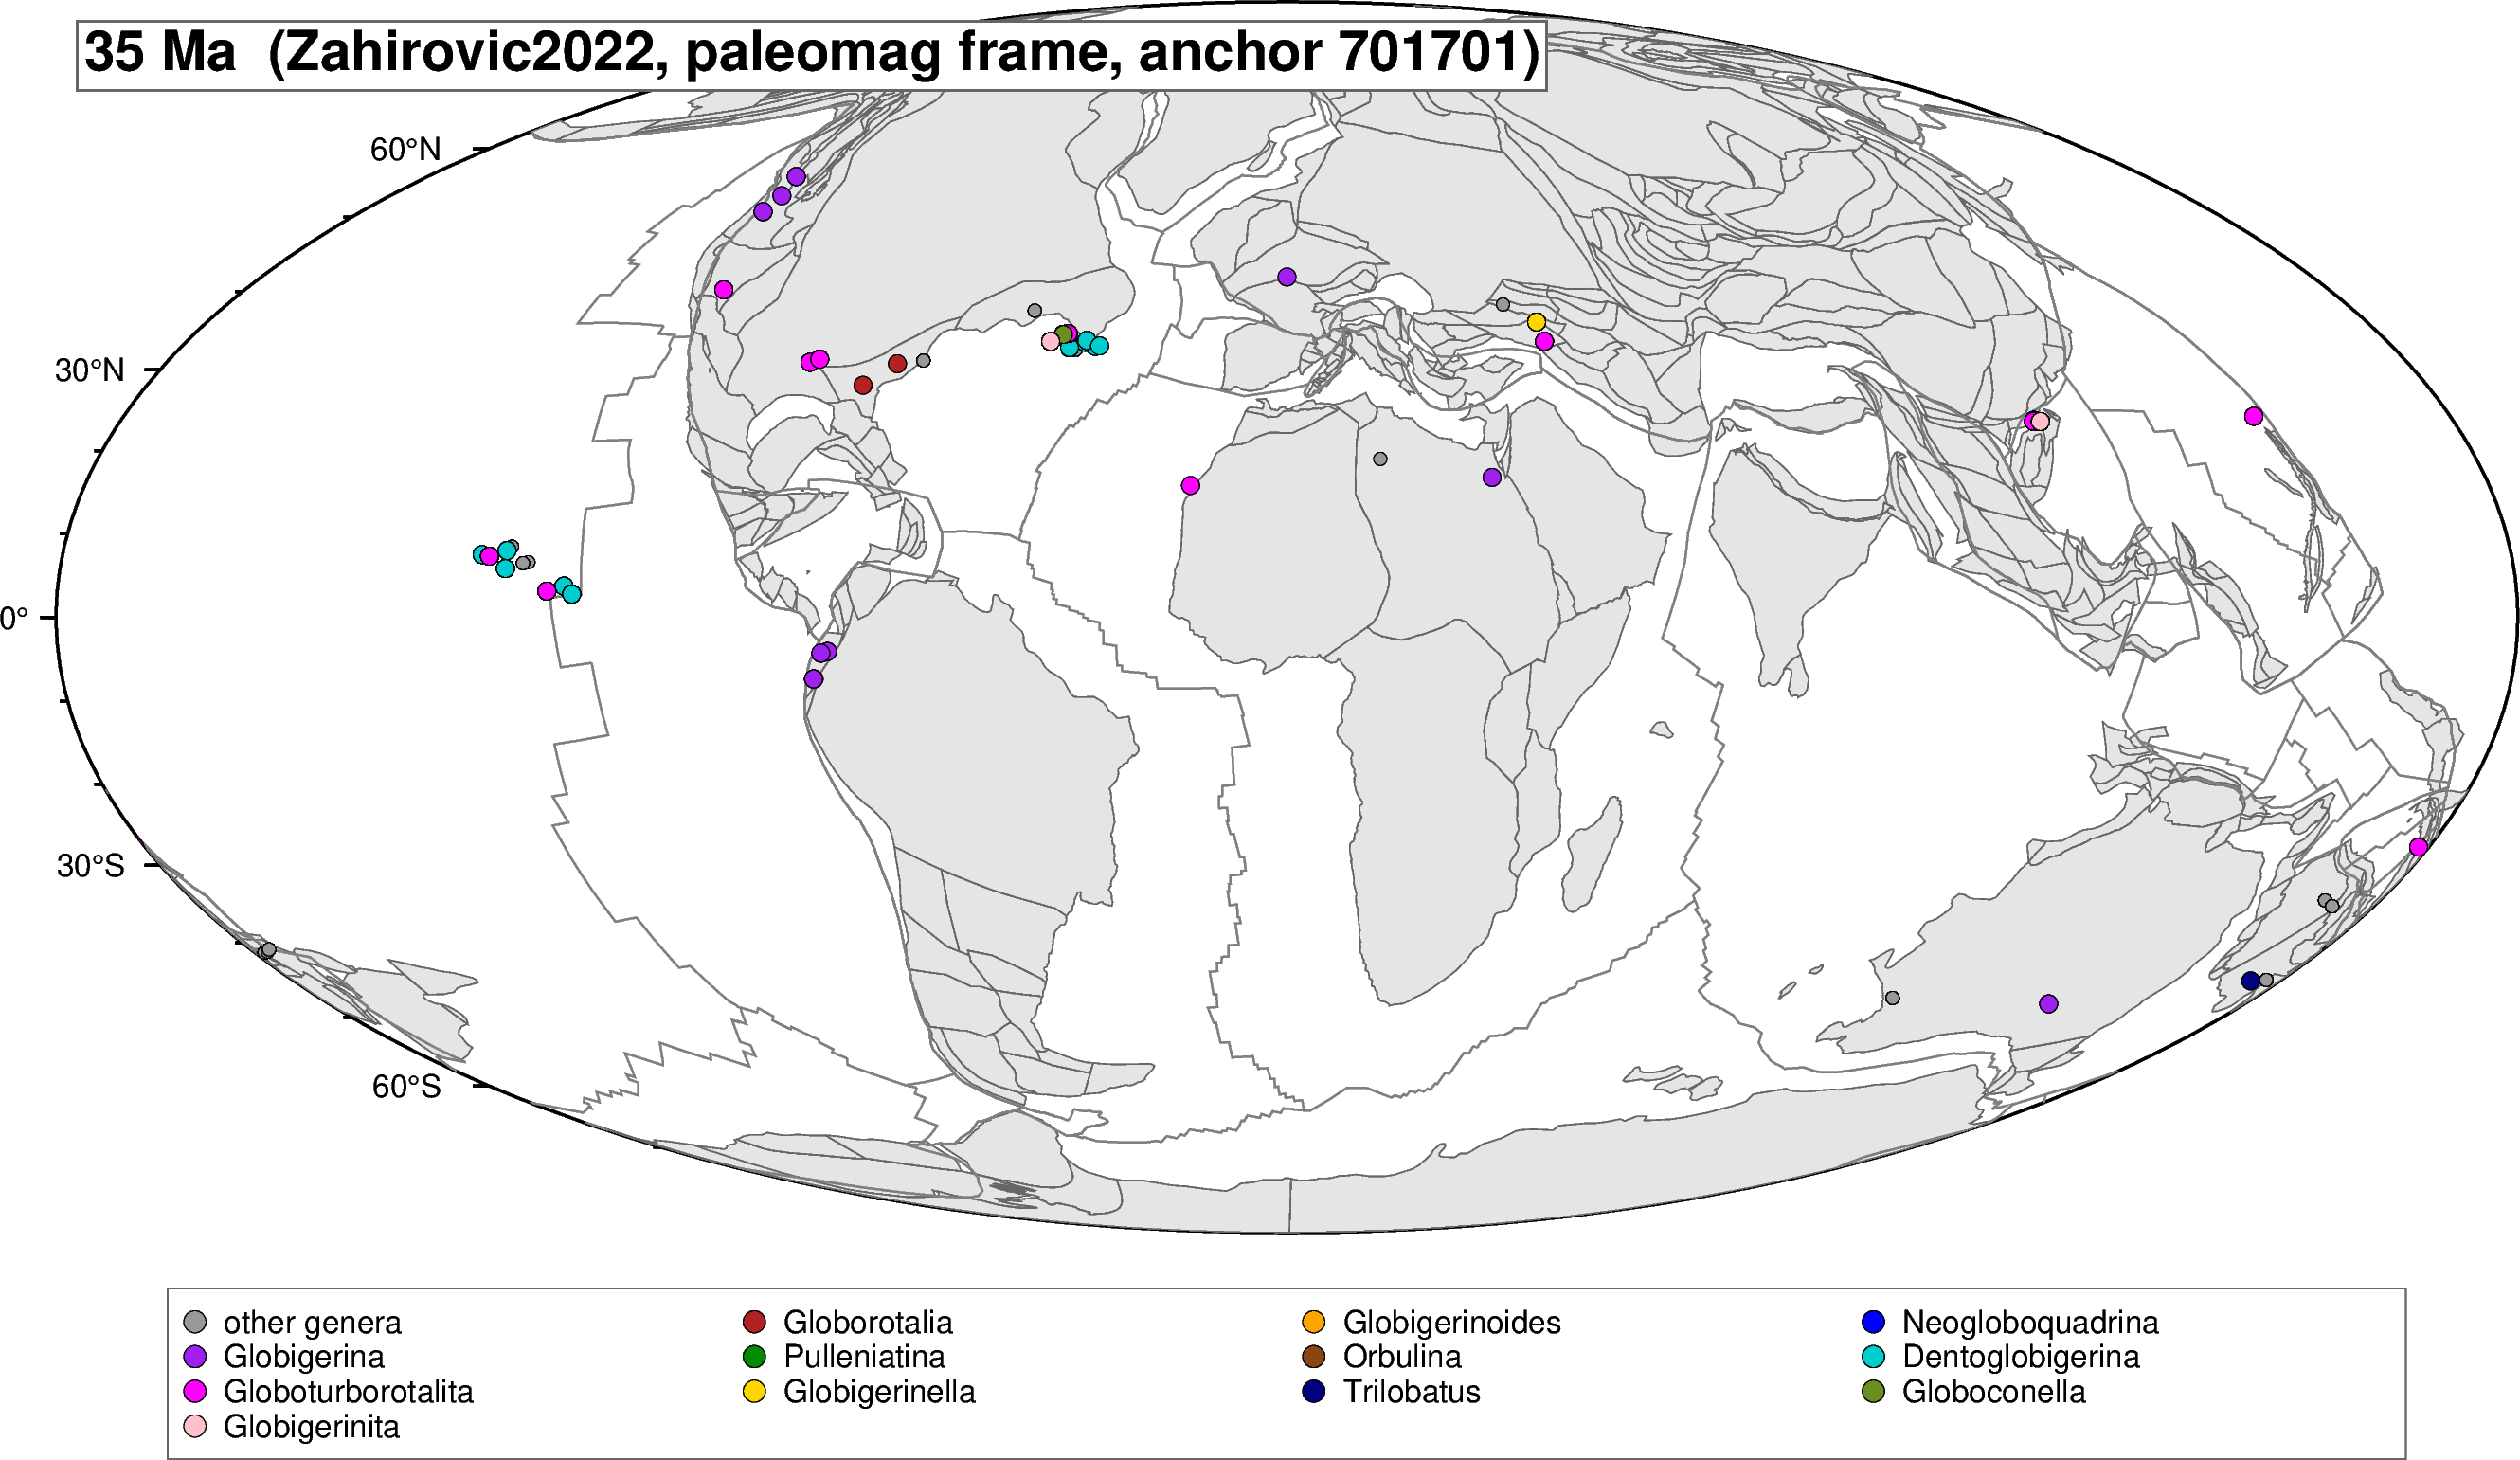

  10 Ma: 13,842 occurrences in ±5 Myr window


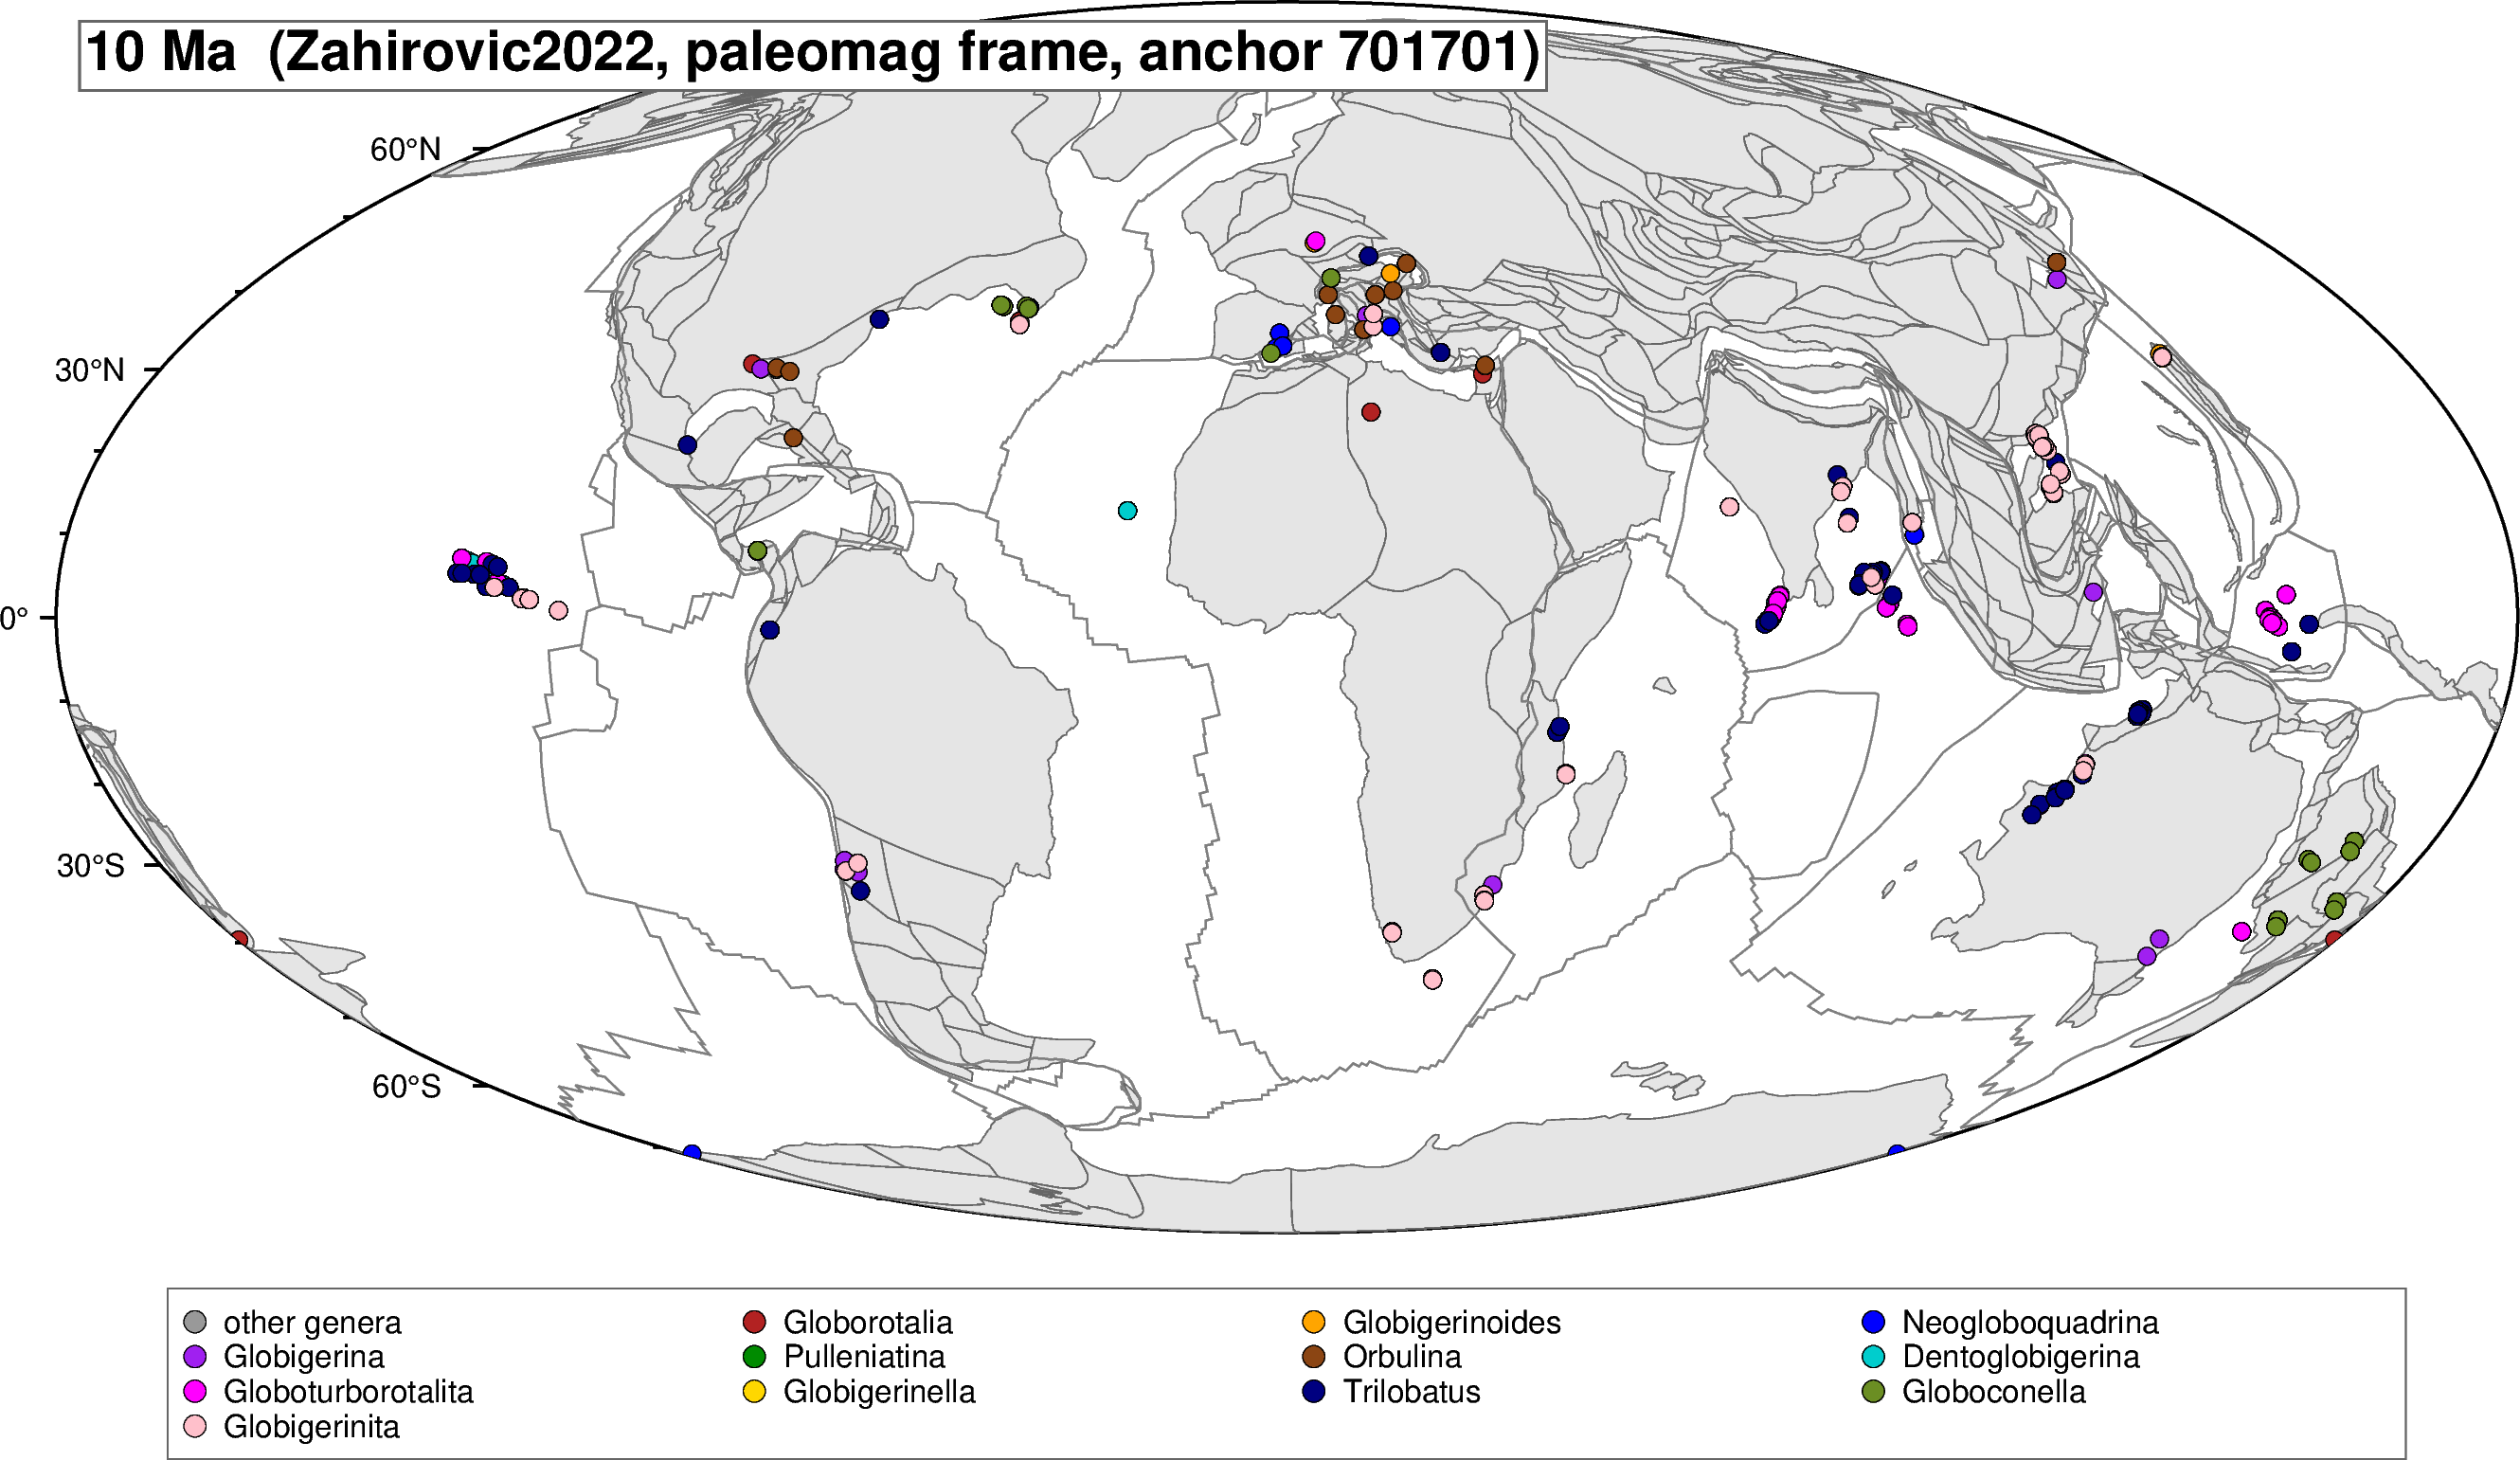

In [5]:
# Cell 4 — three snapshots
# The 12 most common genera get their own colour; all others are grey.
_PALETTE = ["firebrick", "orange", "blue", "purple", "green4", "saddlebrown",
            "cyan3", "#FF00FF", "gold", "navy", "olivedrab", "pink"]
TOP_GENERA = df["genus"].value_counts().index[:len(_PALETTE)]
GENUS_COLOURS = dict(zip(TOP_GENERA, _PALETTE))

for t in SNAPSHOT_TIMES_MA:
    gplot = gplately.PlotTopologies(
        plate_reconstruction=recon,
        coastlines=model.get_coastlines(),
        continents=model.get_continental_polygons(),
        COBs=model.get_COBs(), time=float(t),
        plot_engine=gplately.PygmtPlotEngine(),
        )

    window = df[(df["age_ma"] >= t - 5) & (df["age_ma"] <= t + 5)]
    print(f"  {t:.0f} Ma: {len(window):,} occurrences in ±5 Myr window")

    fig = pygmt.Figure()
    fig.basemap(region="d", projection="W0/22c", frame=["af"])
    gplot.plot_continents(fig, fill="gray90", pen="0.3p,gray40")
    gplot.plot_all_topological_sections(fig, pen="0.5p,gray50")

    # other genera first (grey), then the 12 most common genera on top
    # (the first legend entry sets a 4-column legend)
    ncol = "+N4"
    other = window[~window["genus"].isin(TOP_GENERA)]
    if len(other):
        fig.plot(x=other["paleo_lon"], y=other["paleo_lat"], style="c0.12c",
                 fill="gray60", pen="0.2p,black", label=f"other genera+S0.2c{ncol}")
        ncol = ""
    for genus in TOP_GENERA:
        gdf = window[window["genus"] == genus]
        if len(gdf):
            fig.plot(x=gdf["paleo_lon"], y=gdf["paleo_lat"], style="c0.16c",
                     fill=GENUS_COLOURS[genus], pen="0.2p,black", label=f"{genus}+S0.2c{ncol}")
            ncol = ""
    fig.legend(position="JBC+jTC+o0/0.5c+w20c", box="+gwhite+p0.4p,gray40")
    fig.text(text=f"{t:.0f} Ma  ({MODEL_NAME}, paleomag frame, anchor {ANCHOR_PLATE_ID})",
             position="TL", offset="0.25c/-0.25c", justify="TL",
             font="14p,Helvetica-Bold,black",
             fill="white", pen="0.6p,gray40")
    fig.show(width=1100)
    display(HTML('<div style="height:1cm"></div>'))


## 4. Paleo-latitude histogram per epoch — tropical contraction signal

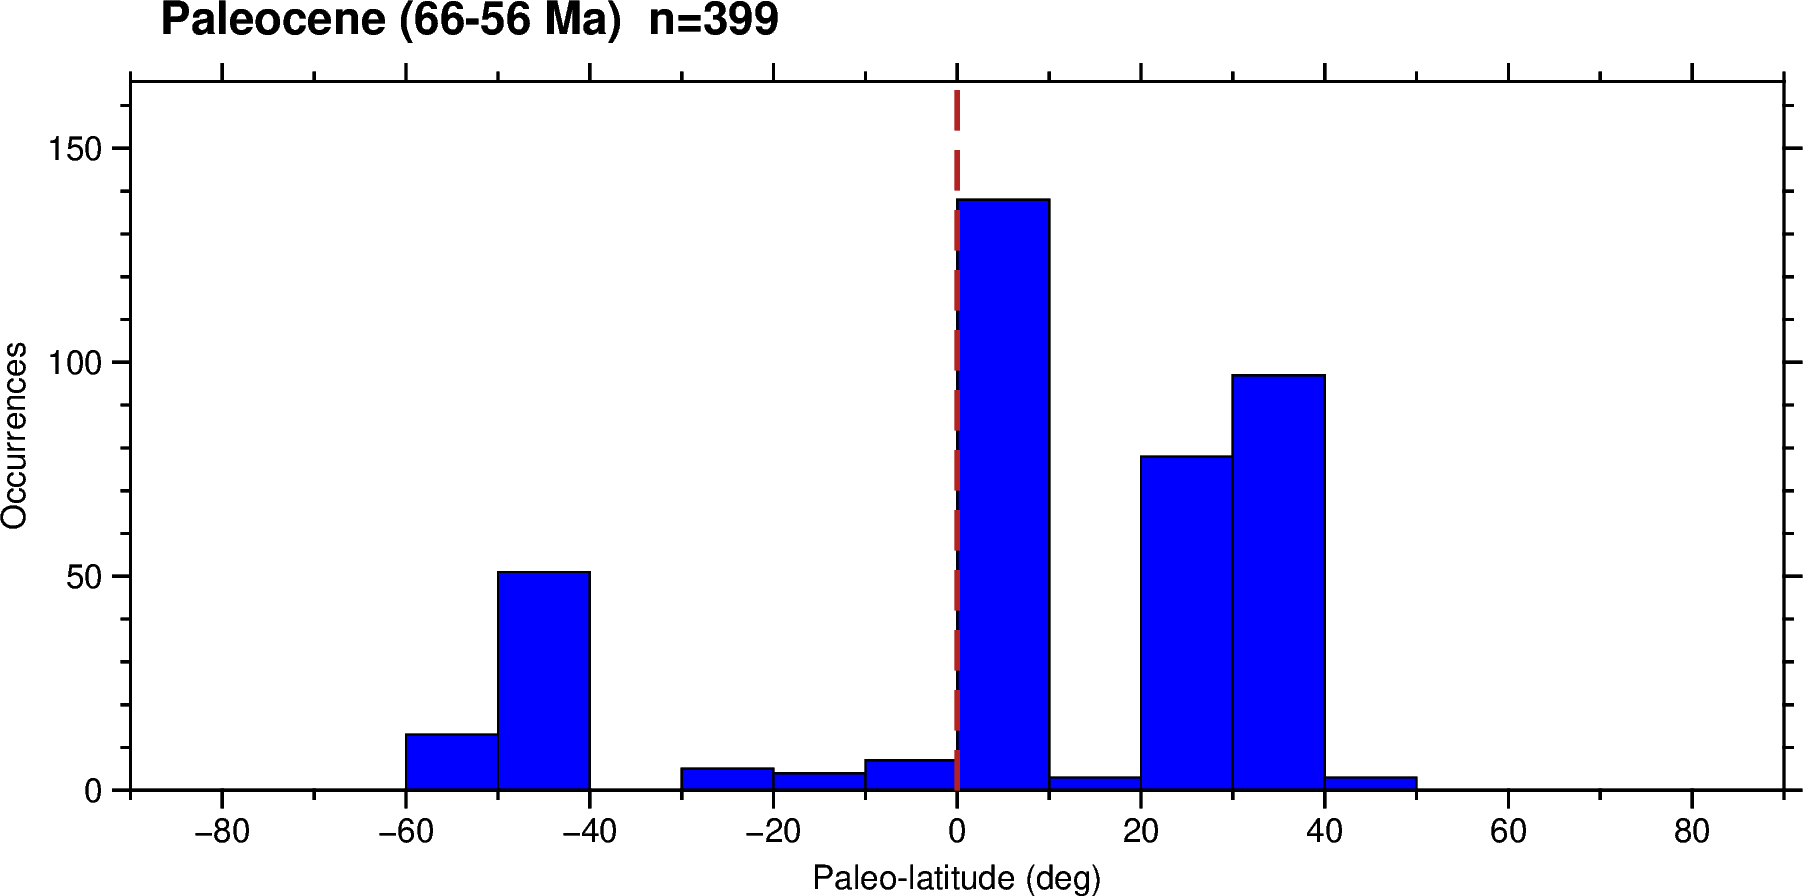

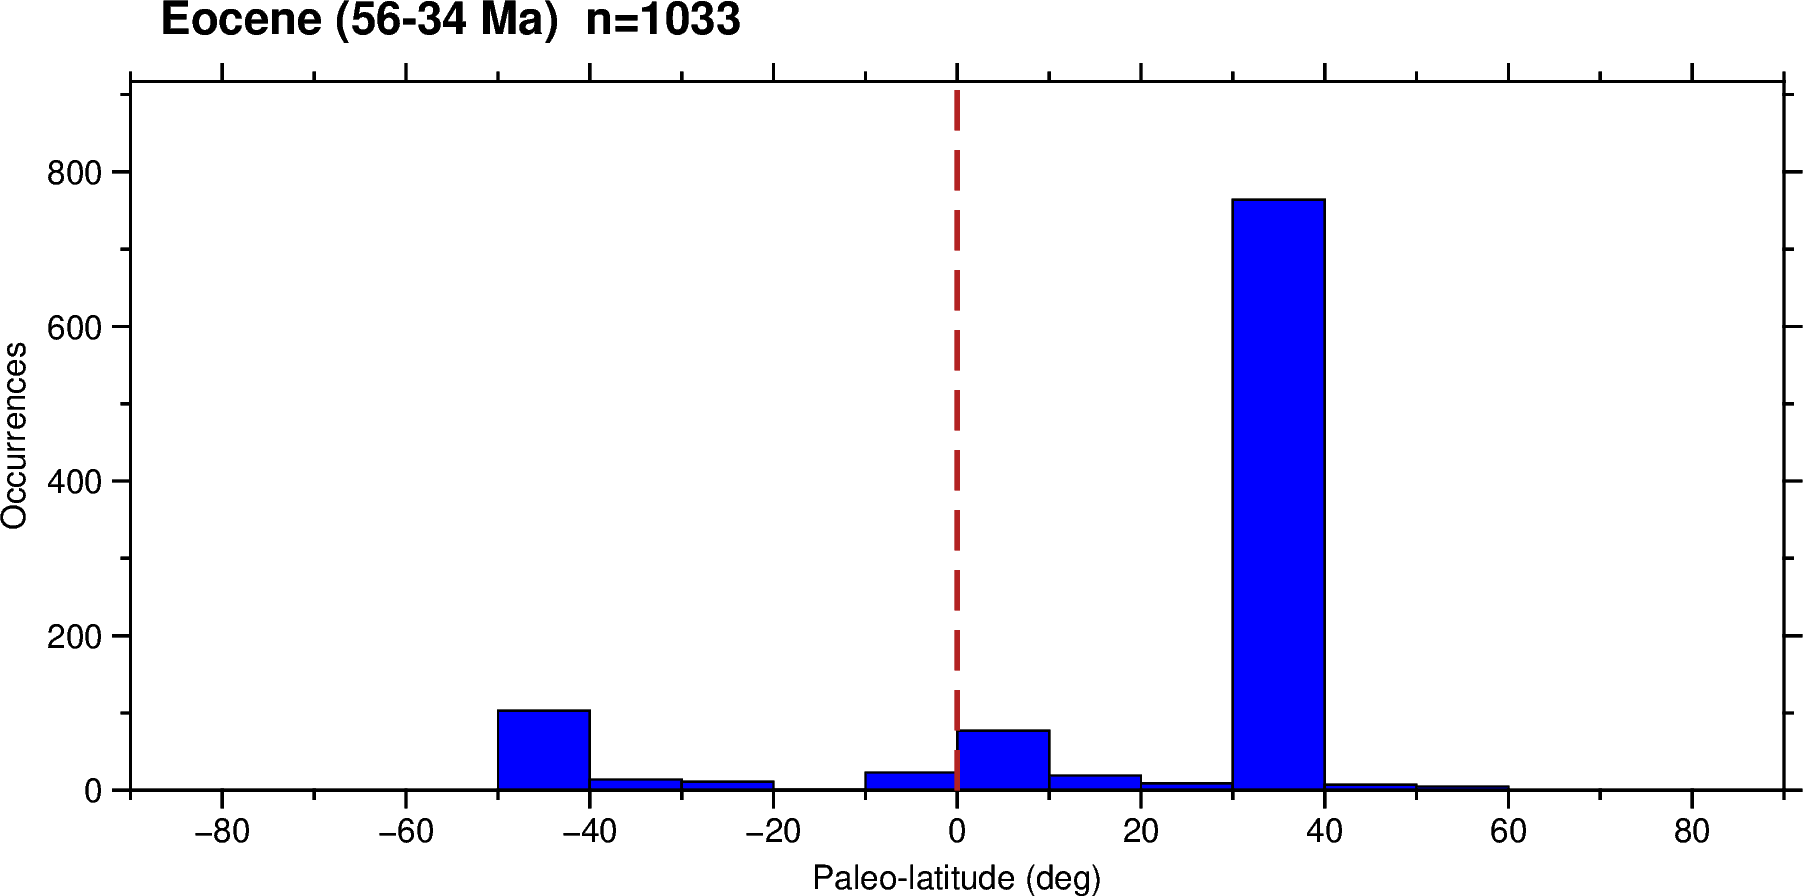

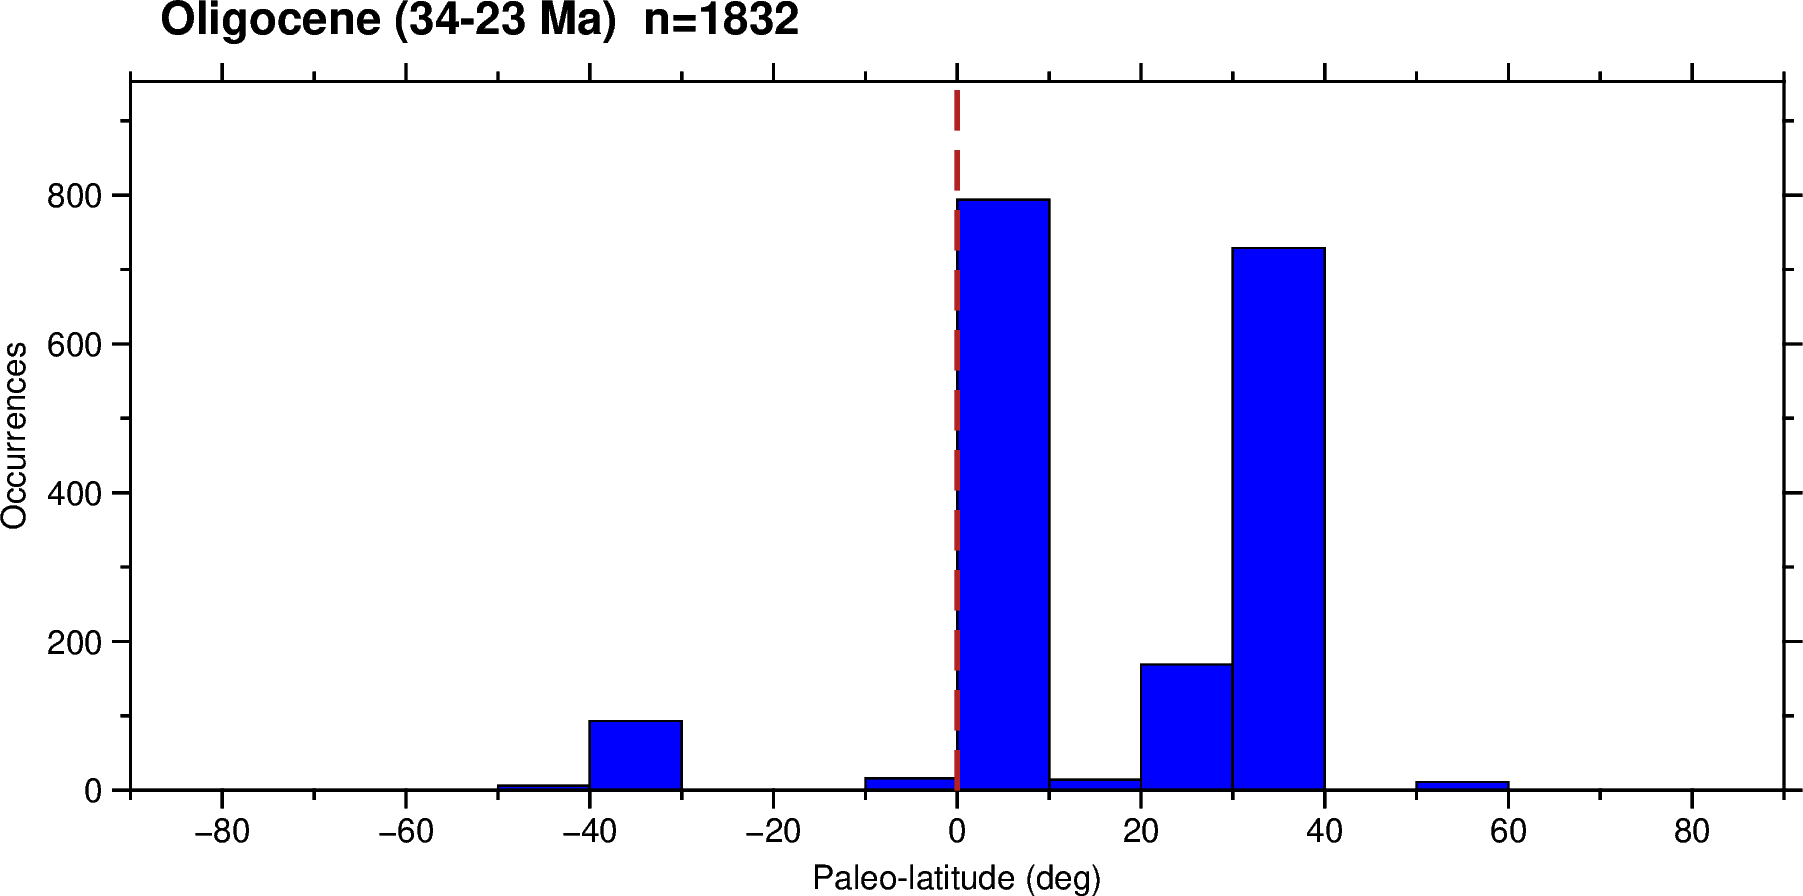

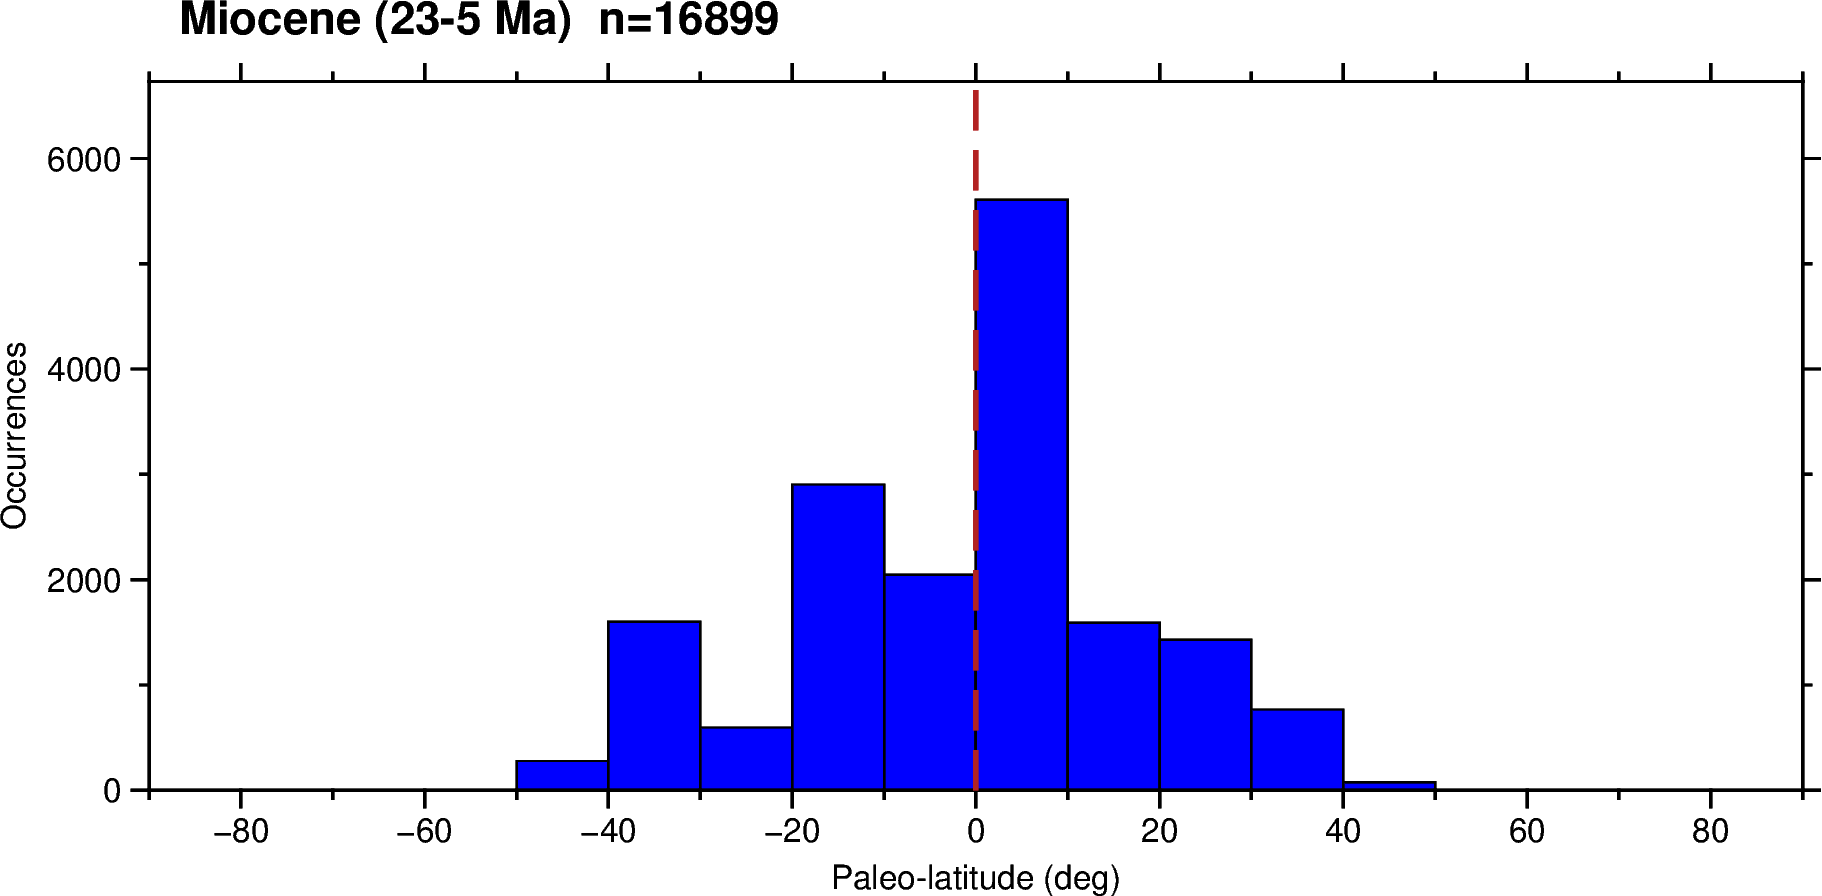

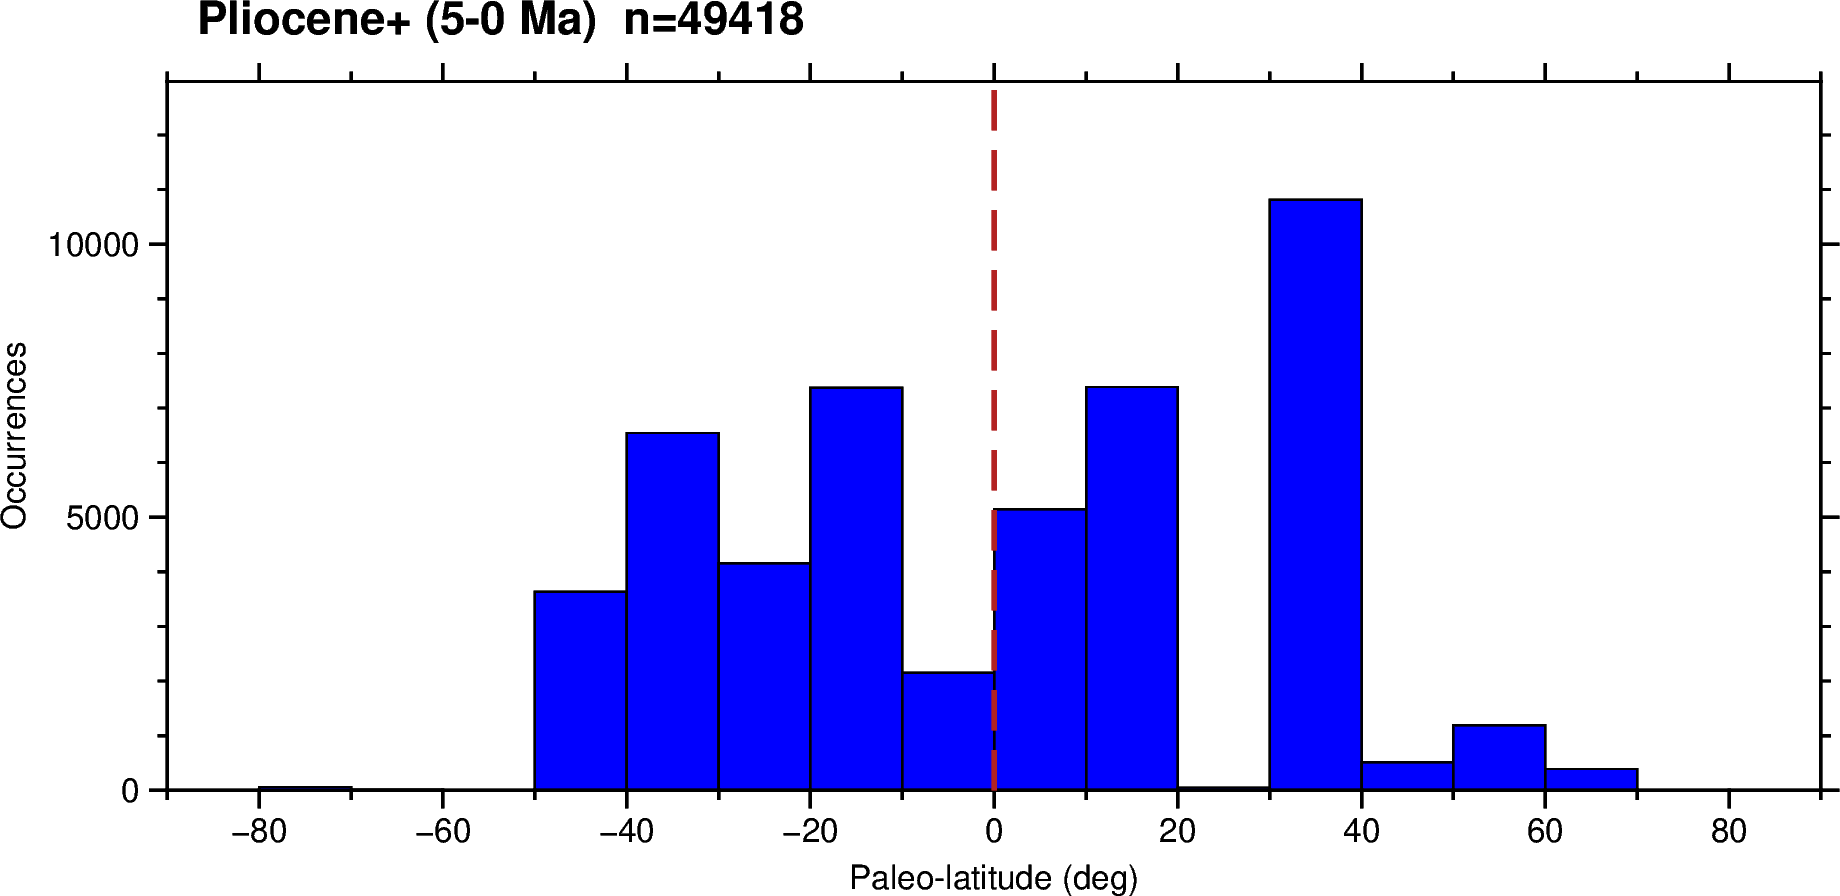

Cenozoic foraminifera — paleo-latitude distribution by epoch (Zahirovic2022)


In [6]:
# Cell 5 — paleolat histograms per epoch (one pygmt.Figure per epoch;
# house style: one panel per figure, no pygmt.subplot).
EPOCHS = [("Paleocene", 56, 66),
          ("Eocene",    34, 56),
          ("Oligocene", 23, 34),
          ("Miocene",    5, 23),
          ("Pliocene+",  0,  5)]

_bin_lo = float(PALEOLAT_BINS[0])
_bin_hi = float(PALEOLAT_BINS[-1])
_bin_w  = float(PALEOLAT_BINS[1] - PALEOLAT_BINS[0])

for name, t0, t1 in EPOCHS:
    win = df[(df["age_ma"] >= t0) & (df["age_ma"] <= t1)]
    data = win["paleo_lat"].to_numpy(float)
    counts, _edges = np.histogram(data, bins=PALEOLAT_BINS)
    ymax = float(max(counts.max(), 1)) * 1.20

    fig = pygmt.Figure()
    fig.histogram(
        data=data,
        region=[_bin_lo, _bin_hi, 0.0, ymax],
        projection="X14c/6c",
        series=f"{_bin_lo}/{_bin_hi}/{_bin_w}",
        fill="blue",
        pen="0.5p,black",
        histtype=0,
        frame=["WSne", "xaf+lPaleo-latitude (deg)", "yaf+lOccurrences"],
    )
    # Equator reference line
    fig.plot(x=[0, 0], y=[0.0, ymax], pen="1.2p,firebrick,dashed")
    fig.text(text=f"{name} ({t1}-{t0} Ma)  n={len(win)}",
             position="TL", offset="0.25c/0.4c", justify="BL",
             font="11p,Helvetica-Bold,black", no_clip=True)
    fig.show(width=700)

# Overall title as a separate one-line print (pyGMT doesn't do figure-level suptitles
# across separate Figure objects).
print(f"Cenozoic foraminifera — paleo-latitude distribution by epoch ({MODEL_NAME})")


## 5. Per-site paleo-latitude trajectories

  sites: 342-U1403 (63 Myr), 342-U1406 (47 Myr), 342-U1407 (61 Myr), 342-U1408 (56 Myr), 355-U1457 (61 Myr), 362-U1480 (63 Myr), 369-U1514 (60 Myr), 371-U1506 (44 Myr), 371-U1508 (43 Myr), 371-U1509 (60 Myr), 371-U1511 (60 Myr), 375-U1520 (63 Myr)


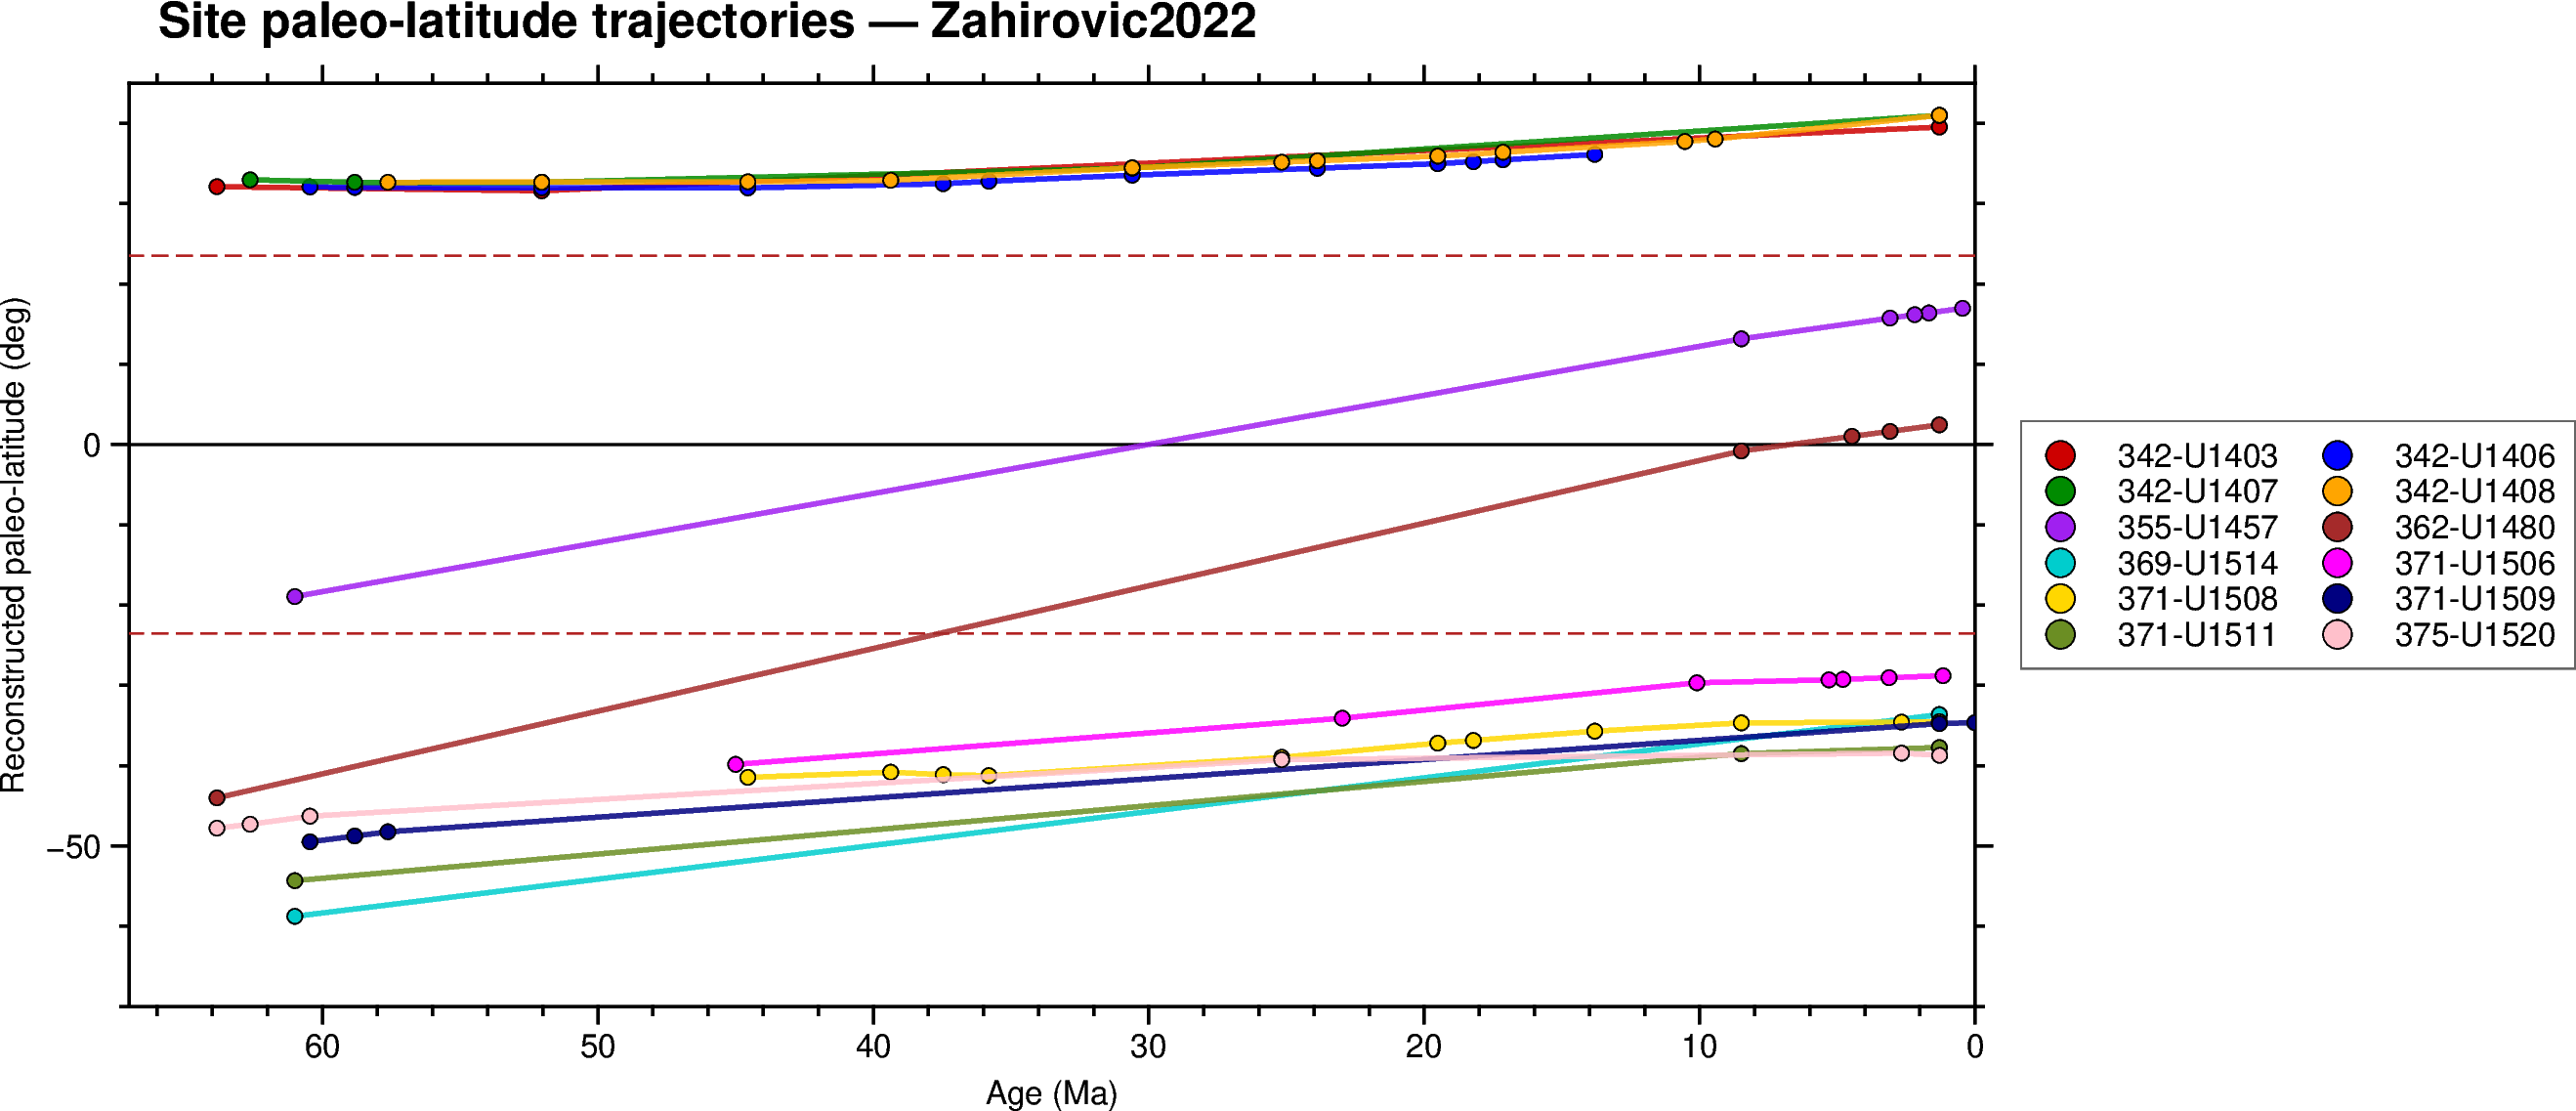

In [7]:
# Cell 6 — per-site paleo-latitude trajectories, one pygmt.Figure.
# Colour palette: hand-picked 20-colour categorical set (analogous to tab20).
_SITE_COLORS = [
    "red3", "blue", "green4", "orange", "purple",
    "brown", "cyan3", "#FF00FF", "gold", "navy",
    "olivedrab", "pink", "gray40", "green", "brown",
    "cyan", "purple", "orange", "blue", "brown",
]

# the drill sites whose samples span the longest age range
_span = df.dropna(subset=["site"]).groupby("site")["age_ma"].agg(lambda a: a.max() - a.min())
sites = sorted(_span.sort_values(ascending=False).index[:N_TRAJECTORY_SITES])
print("  sites:", ", ".join(f"{s} ({_span[s]:.0f} Myr)" for s in sites))
age_max_pad = float(df.loc[df.site.isin(sites), "age_ma"].max()) * 1.05
age_max_pad = max(age_max_pad, 1.0)

fig = pygmt.Figure()
# Negative projection width inverts the x axis (invert_xaxis analog):
# older ages on the LEFT, younger on the RIGHT.
fig.basemap(region=[0.0, age_max_pad, -70.0, 45.0],
            projection="X-16c/8c",
            frame=["WSne", "xaf+lAge (Ma)", "yaf+lReconstructed paleo-latitude (deg)"])
# Equator + tropical reference lines (Tropic of Cancer/Capricorn at 23.5)
fig.plot(x=[0.0, age_max_pad], y=[0.0, 0.0],   pen="0.6p,black")
fig.plot(x=[0.0, age_max_pad], y=[23.5, 23.5], pen="0.5p,firebrick,dashed")
fig.plot(x=[0.0, age_max_pad], y=[-23.5, -23.5], pen="0.5p,firebrick,dashed")

# Build a legend spec file to render on the right.
import tempfile
legend_lines = ["N 2"]  # 2-column legend
for i, s in enumerate(sites):
    # one point per sample age (all occurrences of a sample share its paleo-position)
    sdf = df[df.site == s].groupby("age_ma", as_index=False)["paleo_lat"].mean().sort_values("age_ma")
    if sdf.empty:
        continue
    col = _SITE_COLORS[i % len(_SITE_COLORS)]
    x = sdf["age_ma"].to_numpy(float)
    y = sdf["paleo_lat"].to_numpy(float)
    fig.plot(x=x, y=y, pen=f"1.2p,{col}", transparency=15)
    fig.plot(x=x, y=y, style="c0.13c", fill=col, pen="0.3p,black")
    legend_lines.append(f"S 0.2c c 0.25c {col} 0.3p,black 0.7c {s}")

_legend_str = "\n".join(legend_lines) + "\n"
with tempfile.NamedTemporaryFile("w", suffix=".txt", delete=False) as _lf:
    _lf.write(_legend_str)
    _lpath = _lf.name

fig.legend(spec=_lpath, position="JMR+jML+o0.4c/0c+w4.8c",
           box="+gwhite+p0.4p,gray40")

fig.text(text=f"Site paleo-latitude trajectories — {MODEL_NAME}",
         position="TL", offset="0.25c/0.4c", justify="BL",
         font="12p,Helvetica-Bold,black", no_clip=True)
fig.show(width=1000)


## Extend this

- **Other taxa.** Change `TAXA` to another group PBDB knows (for example `"Radiolaria"` or `"Coccolithophyceae"`); the rest of the notebook is unchanged.
- **Neptune Sandbox NSB.** Same workflow with Neptune's DSDP/ODP/IODP-aligned taxonomy and age models. Register at https://www.nsb-mfn-berlin.de/ and download the CSV export.
- **Counter-point: the Holocene/LGM no-op.** Restrict the table to `age_ma <= 0.02` and re-run. The reconstruction step contributes nothing — the critique of the original I04.

## References

- Paleobiology Database (PBDB) — community-curated fossil-occurrence database, https://paleobiodb.org/ (data CC BY 4.0).
- Lazarus, D. (1994). Neptune: A marine micropaleontology database. *Mathematical Geology* 26, 817-832. https://doi.org/10.1007/BF02083119
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
- Cramer, B.S. et al. (2009). Ocean overturning since the Late Cretaceous. *Paleoceanography* 24, PA4216.  *(Cenozoic cooling reference.)*
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3-10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515